# Chapter 7 — Predictive Models

This notebook explores these applications on a chemical process:

1. Knowledge-based modeling
2. Data-driven modeling
3. Surrogate modeling
4. Hybrid modeling
5. Parameter estimation — Jaya
6. Model interpretation — Sobol and SHAP

The examples implemented below cover hybrid modeling, Jaya and Sobol analysis. SHAP is listed as a topic for further work.

| Model | What it knows |
|---|---|
| Knowledge-based | Only the physics supplied to it |
| Data-driven | Only the patterns observed in the data |
| Hybrid | Physics plus a correction learned from data |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

R = 8.314  # J/(mol·K)

In [2]:
# True system parameters, normally unknown to us
k0_true = 2.5e6       # 1/s
Ea_true = 55_000      # J/mol


def true_process(T, C_A):
    """Synthetic function representing the underlying physical process."""
    
    k = k0_true * np.exp(-Ea_true / (R * T))
    
    # An effect not captured by the simple Arrhenius model
    nonideality = 1 + 0.20 * np.sin((T - 320) / 55)
    
    return k * C_A * nonideality # Calculate reaction rate from temperature and concentration.

The `nonideality` term represents effects that might occur in a real system but are absent from our simplified model:

- Mass transfer
- Catalyst behavior
- Side reactions
- Other physical effects that we cannot measure

In [3]:
n_samples = 150

T = rng.uniform(320, 500, n_samples) # Generate n_samples random temperatures between 320 K and 500 K.
C_A = rng.uniform(0.2, 2.0, n_samples)

r_clean = true_process(T, C_A)

# Approximately 4% experimental measurement error
measurement_error = rng.normal(0, 0.04, n_samples)
r_observed = r_clean * (1 + measurement_error)

data = pd.DataFrame({
    "temperature_K": T,
    "concentration_mol_L": C_A,
    "reaction_rate": r_observed
})

data.head()

,temperature_K,concentration_mol_L,reaction_rate
0,459.312089,1.687325,2.582437
1,398.998119,1.813089,0.340822
2,474.547626,0.452448,1.052692
3,445.526245,1.197265,1.234394
4,336.951923,0.395436,0.003303


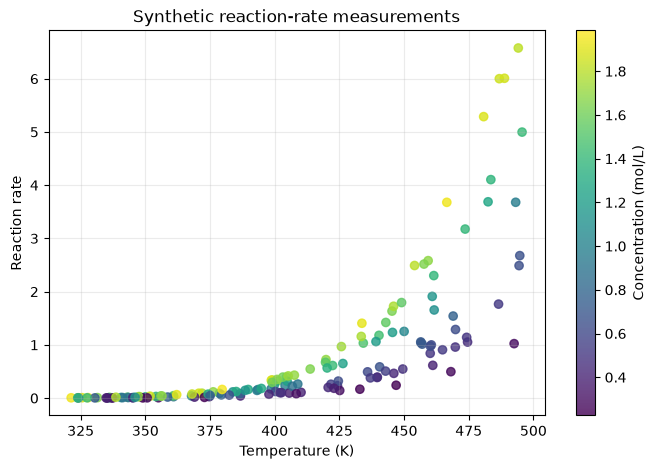

In [4]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    data["temperature_K"],
    data["reaction_rate"],
    c=data["concentration_mol_L"],
    cmap="viridis",
    alpha=0.8
)

plt.colorbar(scatter, label="Concentration (mol/L)")
plt.xlabel("Temperature (K)")
plt.ylabel("Reaction rate")
plt.title("Synthetic reaction-rate measurements")
plt.grid(alpha=0.25)
plt.show()

In the plot we expect to see:

- Reaction rate rises strongly as temperature increases.
- At the same temperature, observations with higher concentration have higher rates.
- The relationship is nonlinear.

In [5]:
#Knowledge-based model
k0_assumed = 2.0e6
Ea_assumed = 53_000


def knowledge_based_model(T, C_A):
    """Simplified model based on physical knowledge."""
    
    k = k0_assumed * np.exp(-Ea_assumed / (R * T))
    return k * C_A


data["knowledge_prediction"] = knowledge_based_model(
    data["temperature_K"],
    data["concentration_mol_L"]
)

### Nonideal Effects in the Model

The `nonideality` term used in the code is not a standard chemical equation. It is an artificial effect created specifically for this example.

It can represent effects in a real process that the simple Arrhenius model does not capture:

- Mass transfer
- Catalyst behavior
- Side reactions
- Phase behavior
- Activity coefficients
- Other unknown temperature effects

We generated the synthetic experimental data using:

$$
r_{\mathrm{true}}=k_0\exp\left(-\frac{E_a}{RT}\right)C_A\times\mathrm{nonideality}
$$

Here:

- $r_{\mathrm{true}}$: observed reaction rate
- $k_0$: pre-exponential factor
- $E_a$: activation energy
- $R$: universal gas constant
- $T$: temperature
- $C_A$: concentration of component A
- $\mathrm{nonideality}$: effects absent from the simple kinetic model

The knowledge-based model uses only basic Arrhenius kinetics:

$$
r_{\mathrm{model}}=k_0\exp\left(-\frac{E_a}{RT}\right)C_A
$$

The model knows the basic chemical relationship but does not include every effect in the system. Therefore, a difference arises between the reaction rate and the model prediction:

$$
e=r_{\mathrm{true}}-r_{\mathrm{model}}
$$

Here $e$ is the **residual**, the part the model does not explain. The hybrid model aims to learn that part from data:

$$
\mathrm{Hybrid\ Model}=\mathrm{Knowledge\text{-}Based\ Model}+\mathrm{Data\text{-}Driven\ Correction}
$$

In other words:

$$
\hat r_{\mathrm{hybrid}}=\hat r_{\mathrm{physics}}+\hat e_{\mathrm{ML}}
$$

Here $\hat e_{\mathrm{ML}}$ is the correction predicted by a machine learning model.

> **Note:** We have not simulated an entire reactor or solved time-dependent concentration, volume, or energy balances. We modeled only the instantaneous reaction rate at different $T$ and $C_A$ conditions, a first step in kinetic modeling.

In [6]:
errors = data["reaction_rate"] - data["knowledge_prediction"]

rmse = np.sqrt(np.mean(errors**2))

ss_res = np.sum(errors**2)
ss_tot = np.sum(
    (data["reaction_rate"] - data["reaction_rate"].mean())**2
)

r2 = 1 - ss_res / ss_tot

print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

RMSE: 0.4398
R²:   0.8781


## Examining Errors in the Knowledge-Based Model

RMSE and $R^2$ alone are not enough to evaluate model performance. We also need to examine which operating conditions produce errors. We use two plots:

1. Observed versus predicted reaction rate
2. Residual versus temperature

The residual is defined as:

$$
e_i=y_i-\hat{y}_i
$$

- $e_i>0$: the model underpredicts the observed value.
- $e_i<0$: the model overpredicts the observed value.
- $e_i\approx0$: the prediction is close to the observation.

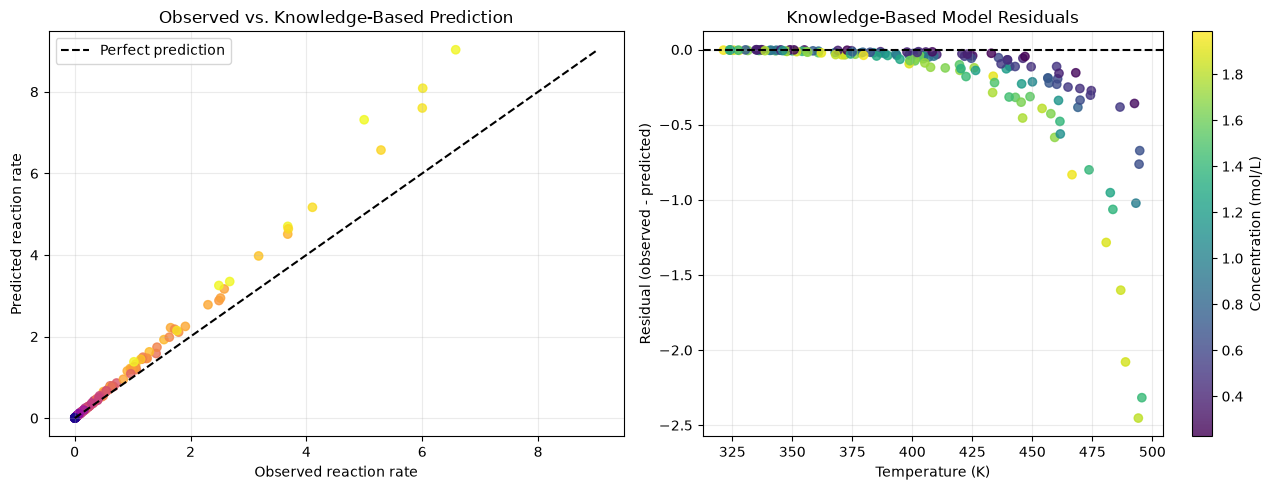

In [7]:
# Observed values, predictions, and residuals
y_observed = data["reaction_rate"]
y_knowledge = data["knowledge_prediction"]

data["knowledge_residual"] = y_observed - y_knowledge


fig, axes = plt.subplots(1, 2, figsize=(13, 5))


# --------------------------------------------------
# 1. Observed versus predicted values
# --------------------------------------------------

axes[0].scatter(
    y_observed,
    y_knowledge,
    c=data["temperature_K"],
    cmap="plasma",
    alpha=0.8
)

minimum_value = min(y_observed.min(), y_knowledge.min())
maximum_value = max(y_observed.max(), y_knowledge.max())

axes[0].plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    color="black",
    label="Perfect prediction"
)

axes[0].set_xlabel("Observed reaction rate")
axes[0].set_ylabel("Predicted reaction rate")
axes[0].set_title("Observed vs. Knowledge-Based Prediction")
axes[0].legend()
axes[0].grid(alpha=0.25)


# --------------------------------------------------
# 2. Residual versus temperature
# --------------------------------------------------

residual_plot = axes[1].scatter(
    data["temperature_K"],
    data["knowledge_residual"],
    c=data["concentration_mol_L"],
    cmap="viridis",
    alpha=0.8
)

axes[1].axhline(
    y=0,
    linestyle="--",
    color="black"
)

axes[1].set_xlabel("Temperature (K)")
axes[1].set_ylabel("Residual (observed - predicted)")
axes[1].set_title("Knowledge-Based Model Residuals")
axes[1].grid(alpha=0.25)

fig.colorbar(
    residual_plot,
    ax=axes[1],
    label="Concentration (mol/L)"
)

plt.tight_layout()
plt.show()

The model overpredicts particularly at high reaction rates. Point color represents temperature: yellow points correspond to higher temperatures. Their greater distance from the diagonal suggests that the knowledge-based model's errors grow at high temperatures.

For a good model, we would expect residuals to be scattered randomly around zero. Here they show a distinct downward curve as temperature rises. This pattern suggests that the error is not only random measurement noise; there is a systematic limitation in the model structure or parameters. The model captures the general effect of temperature but not its full shape.

## 7.9 Practice

## Chapter 7.9 — Simplified Hybrid Fuel Cell Model

### Aim

In this experiment I explore hybrid modeling by **using a prediction learned from data in a physical equation**. The book's Section 7.9 connects material properties with fuel cell performance in this way.

### Model idea

Fuel cell voltage is calculated by subtracting losses from the ideal potential:

$$
E(i)=E_{\mathrm{oc}}-\eta_{\mathrm{ac}}-\eta_{\mathrm{tc}}-\eta_{\mathrm{ohm}}
$$

Here I focus only on **ohmic loss**:

$$
\eta_{\mathrm{ohm}}=i\left(\frac{\delta_{\mathrm{mem}}}{\kappa_{\mathrm{mem}}}+\frac{\delta_{\mathrm{io}}}{\kappa_{\mathrm{io}}}\right)
$$

Here $i$ is current density, $\delta$ is layer thickness, and $\kappa$ is conductivity. I expect ohmic loss to decrease as conductivity increases.

### Steps

1. Generate **synthetic conductivity data** as a function of IEC and temperature.
2. Train an SVR model to predict conductivity from IEC and temperature, and evaluate it on a separate test set.
3. Insert predicted conductivities into the ohmic loss equation.
4. Plot how the loss and simplified voltage change with current density.
5. Vary temperature, IEC, or layer thickness individually to examine sensitivity.

### Scope of the experiment

The data are synthetic, so the results **are not predictions of a real fuel cell's performance**. Other voltage losses are not yet modeled. The aim is not to reproduce the book's results exactly; it is to understand the following chain:

**Material inputs → conductivity predicted by ML → ohmic loss calculated by equation → voltage curve → interpretation.**

In [8]:

# %pip install numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, r2_score

rng = np.random.default_rng(42)  # Use the same synthetic data on each run

print("Ready! Libraries loaded.")

Ready! Libraries loaded.


In [9]:
n_samples = 130

# Model inputs
iec = rng.uniform(0.8, 2.0, n_samples)       # meq/g
temperature = rng.uniform(120, 180, n_samples)  # °C

# Relationship defined for this learning experiment; not a real material law
kappa_clean = (
    0.025
    + 0.028 * (iec - 0.8)
    + 0.00035 * (temperature - 120)
    + 0.00022 * (iec - 0.8) * (temperature - 120)
)

# Simulate small measurement deviations
kappa_measured = kappa_clean + rng.normal(0, 0.002, n_samples) # Add random deviations to the calculated values.

df = pd.DataFrame({ # Combine the three arrays in a Pandas table.
    "IEC": iec,
    "T_C": temperature,
    "kappa_S_cm": kappa_measured,
})

display(df.head()) # Display the first five rows.
print(f"Data shape: {df.shape[0]} rows, {df.shape[1]} columns")

,IEC,T_C,kappa_S_cm
0,1.728747,130.235578,0.057362
1,1.326654,175.507207,0.069063
2,1.830318,154.863668,0.071980
3,1.636842,140.812188,0.059057
4,0.913013,155.454929,0.043010


Data shape: 130 rows, 3 columns


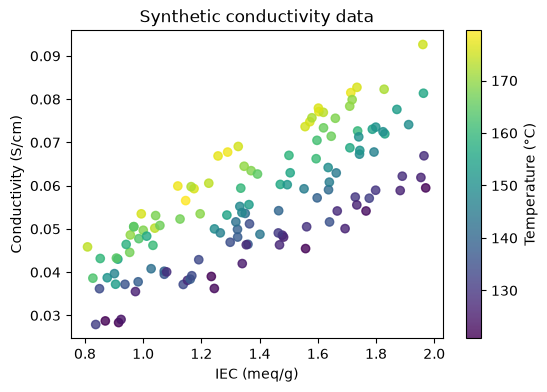

In [10]:
plt.figure(figsize=(6, 4))

points = plt.scatter(
    df["IEC"],
    df["kappa_S_cm"],
    c=df["T_C"],
    cmap="viridis",
    alpha=0.8,
)

plt.colorbar(points, label="Temperature (°C)")
plt.xlabel("IEC (meq/g)")
plt.ylabel("Conductivity (S/cm)")
plt.title("Synthetic conductivity data")
plt.show()

### Interpreting the Plot

Each point represents a synthetic material sample. The horizontal axis shows **IEC**, the vertical axis shows **conductivity**, and color shows temperature: purple is lower and yellow is higher.

Conductivity generally increases with IEC. Warmer samples also tend to have higher conductivity. The points do not form a single line because samples have different IEC and temperature values, and we added small random variations to the synthetic measurements.

This is consistent with the trend we expect the SVR model to learn. The plot currently shows only generated data, not model predictions. Since the data are synthetic, this relationship does not establish real fuel cell behavior.

In [11]:
X = df[["IEC", "T_C"]]
y = df["kappa_S_cm"] # X contains IEC and temperature; y is the conductivity to predict.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=100, epsilon=0.001)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test) # Predict conductivity for the 26 previously unseen test samples.

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred) # Measure how well predictions explain variation in the test data.

print(f"Test samples: {len(X_test)}")
print(f"Test MAE: {mae:.4f} S/cm")
print(f"Test R²:  {r2:.3f}")

Test samples: 26
Test MAE: 0.0021 S/cm
Test R²:  0.964


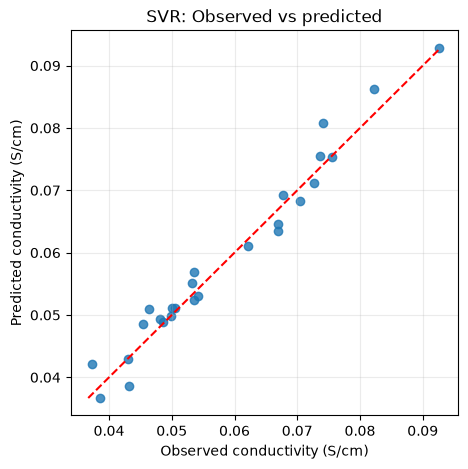

In [12]:

# The horizontal axis shows observed conductivity and the vertical axis shows predictions. The dashed red line represents perfect predictions; distance from it visualizes prediction error.
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.8)

# Perfect prediction line
plt.plot([lower, upper], [lower, upper], "--", color="red")

plt.xlabel("Observed conductivity (S/cm)")
plt.ylabel("Predicted conductivity (S/cm)")
plt.title("SVR: Observed vs predicted")
plt.grid(alpha=0.25)
plt.show()

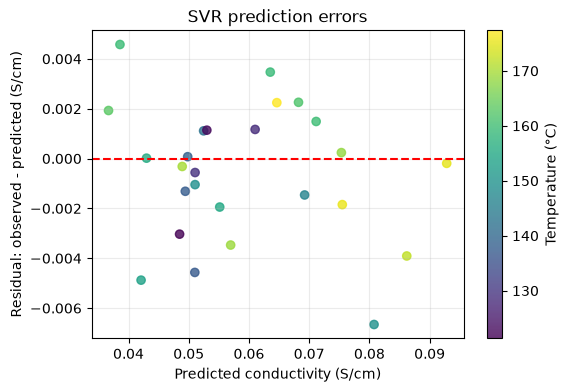

In [13]:
# SVR prediction errors
# Calculate differences between predicted and observed values to assess performance.
# Use temperature as color to visualize its relationship with residuals.
# Temperature may affect prediction errors; relating it to residuals helps interpret performance.
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(6, 4))

points = plt.scatter(
    y_pred,
    residuals,
    c=X_test["T_C"],
    cmap="viridis",
    alpha=0.8,
)

plt.axhline(0, linestyle="--", color="red")
plt.colorbar(points, label="Temperature (°C)")
plt.xlabel("Predicted conductivity (S/cm)")
plt.ylabel("Residual: observed - predicted (S/cm)")
plt.title("SVR prediction errors")
plt.grid(alpha=0.25)
plt.show()

The points lie on both sides of the zero line, with no obvious tendency to consistently overpredict or underpredict. The colors also show no clear pattern of errors concentrated at particular temperatures. Errors therefore appear generally balanced on this small test set. Although some deviations are larger, most points are close to zero, consistent with the low MAE.

Predicted conductivity: 0.0566 S/cm


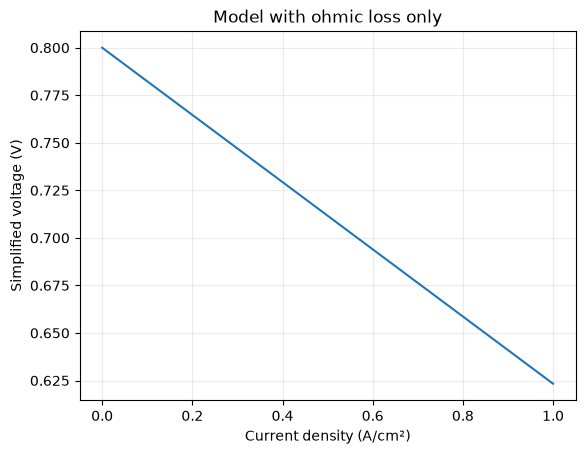

In [14]:
# The previous residual plot shows predicted conductivity on the horizontal axis and residuals on the vertical axis. Color represents temperature and the red dashed line indicates zero error. Distance from this line visualizes error.
# Choose a representative material and operating temperature
sample = pd.DataFrame({"IEC": [1.4], "T_C": [150]})
kappa_ref = model.predict(sample)[0] # Predict conductivity for IEC 1.4 and temperature 150 °C.

# Simplified single-layer assumptions
delta_eff_cm = 0.01 # Effective thickness of the conductive layer, a parameter used in the conductivity calculation.
E_ideal_V = 0.8 # Ideal voltage, a parameter in the simplified model.

current_density = np.linspace(0, 1.0, 100) # Current density, an input to the calculation.
# This parameter can affect model performance.

# Calculate ohmic loss and a voltage containing only ohmic loss
eta_ohm = current_density * delta_eff_cm / kappa_ref
voltage = E_ideal_V - eta_ohm

print(f"Predicted conductivity: {kappa_ref:.4f} S/cm")

plt.plot(current_density, voltage)
plt.xlabel("Current density (A/cm²)")
plt.ylabel("Simplified voltage (V)")
plt.title("Model with ohmic loss only")
plt.grid(alpha=0.25)
plt.show()

## Hybrid Model

In [15]:
# Physics model inputs and the error it does not explain
X_reaction = data[["temperature_K", "concentration_mol_L"]] # Inputs: temperature and concentration.
reaction_residual = data["reaction_rate"] - data["knowledge_prediction"] # Residual unexplained by the physics model.

# Use the same test observations for both models
idx_train, idx_test = train_test_split(
    data.index, test_size=0.2, random_state=42 # Split indices into 80% training and 20% test data; random_state=42 makes the split reproducible.
)

# ML model that predicts the residual
correction_model = make_pipeline( # Standardize inputs and use SVR to predict residuals.
    StandardScaler(),
    SVR(kernel="rbf", C=20, epsilon=0.01) # RBF kernel; C controls the penalty for errors and epsilon defines the insensitive error range.
) 

correction_model.fit(
    X_reaction.loc[idx_train],
    reaction_residual.loc[idx_train]
)

# Hybrid prediction = physics prediction + ML correction
correction = correction_model.predict(X_reaction.loc[idx_test])
knowledge_pred = data.loc[idx_test, "knowledge_prediction"].to_numpy()
hybrid_pred = knowledge_pred + correction
actual = data.loc[idx_test, "reaction_rate"].to_numpy()

print(f"Knowledge-based MAE: {mean_absolute_error(actual, knowledge_pred):.4f}")
print(f"Hybrid MAE:          {mean_absolute_error(actual, hybrid_pred):.4f}")

Knowledge-based MAE: 0.2135
Hybrid MAE:          0.0429


On the same test observations, the SVR correction trained on residuals reduced the mean absolute error by approximately 80%. The ML model learned some of the pattern that the physics model missed.

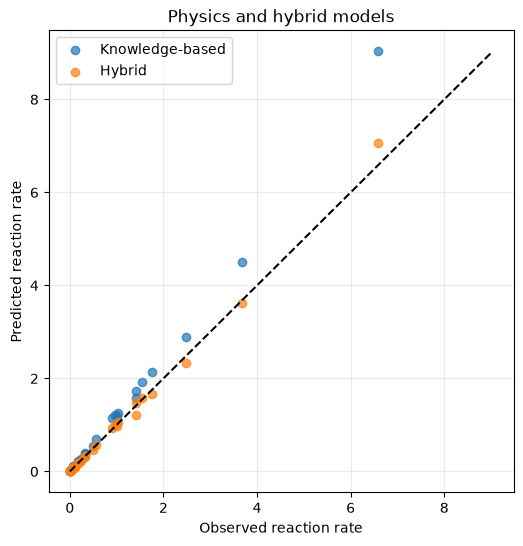

In [16]:
lower = min(actual.min(), knowledge_pred.min(), hybrid_pred.min()) # Set the minimum axis value for the plot.
upper = max(actual.max(), knowledge_pred.max(), hybrid_pred.max()) # Set the maximum axis value for the plot.

plt.figure(figsize=(6, 6))
plt.scatter(actual, knowledge_pred, label="Knowledge-based", alpha=0.7)
plt.scatter(actual, hybrid_pred, label="Hybrid", alpha=0.7)
plt.plot([lower, upper], [lower, upper], "--", color="black")

plt.xlabel("Observed reaction rate")
plt.ylabel("Predicted reaction rate")
plt.title("Physics and hybrid models")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [17]:
# Use Jaya to optimize unknown physical model parameters k0 and Ea. Each iteration updates candidates using the best and worst candidates; report the best parameters and training RMSE.
# Search ranges for k0 and Ea
bounds = np.array([ # Each row gives the minimum and maximum of one parameter.
    [1e6, 4e6],       # k0
    [40_000, 70_000], # Ea
])

def decode(z): # Convert parameters encoded from 0 to 1 to their physical ranges.
    return bounds[:, 0] + z * (bounds[:, 1] - bounds[:, 0]) 
# Take the lower bound of each parameter.
# Take the upper bound of each parameter.
# The return statement maps each element of z to its physical parameter range.
# Jaya searches between 0 and 1; decode maps candidates to the physical ranges above.
T_train = data.loc[idx_train, "temperature_K"].to_numpy() # Select training temperatures by index and convert the Series to a NumPy array.
C_train = data.loc[idx_train, "concentration_mol_L"].to_numpy()
rate_train = data.loc[idx_train, "reaction_rate"].to_numpy()

def objective(z): # Evaluate the quality of a parameter candidate.
     # Decode the candidate, calculate the physics-model predictions, and compute training RMSE; lower RMSE is better.
    k0, Ea = decode(z)
    prediction = k0 * np.exp(-Ea / (R * T_train)) * C_train
    return np.sqrt(np.mean((rate_train - prediction) ** 2))

# Initial Jaya candidates, encoded between 0 and 1
population = rng.random((25, 2)) # Create 25 random candidates for Jaya

for _ in range(80): # Update candidates for 80 iterations
    scores = np.array([objective(candidate) for candidate in population])
    best = population[np.argmin(scores)]
    worst = population[np.argmax(scores)]
    updated = population.copy()

    for j, current in enumerate(population): # For each candidate, use the best and worst candidates to propose an update, then retain it if its objective improves.
        candidate = current + rng.random(2) * (best - current) \
                    - rng.random(2) * (worst - current)
        candidate = np.clip(candidate, 0, 1) # Clip candidate parameters to the interval [0, 1].
        # j: candidate index.
        # current: parameter pair being updated.
        # enumerate returns both index and candidate.



        if objective(candidate) < scores[j]:
            updated[j] = candidate

    population = updated

scores = np.array([objective(candidate) for candidate in population])
best_z = population[np.argmin(scores)]
k0_fit, Ea_fit = decode(best_z)

print(f"k0 found by Jaya: {k0_fit:.0f} 1/s")
print(f"Ea found by Jaya: {Ea_fit:.0f} J/mol")
print(f"Training RMSE: {objective(best_z):.4f}")

k0 found by Jaya: 1000000 1/s
Ea found by Jaya: 51239 J/mol
Training RMSE: 0.0741


In [18]:
# Use Jaya parameters to predict the test data and compare MAE and RMSE with the original assumed parameters.
T_test = data.loc[idx_test, "temperature_K"].to_numpy()
C_test = data.loc[idx_test, "concentration_mol_L"].to_numpy()
rate_test = data.loc[idx_test, "reaction_rate"].to_numpy()

assumed_test = data.loc[idx_test, "knowledge_prediction"].to_numpy()

fitted_test = (
    k0_fit * np.exp(-Ea_fit / (R * T_test)) * C_test
)

for name, prediction in [
    ("Original parameters", assumed_test),
    ("Jaya parameters", fitted_test),
]:
    mae = mean_absolute_error(rate_test, prediction)
    rmse = np.sqrt(np.mean((rate_test - prediction) ** 2))
    print(f"{name}: MAE={mae:.4f}, RMSE={rmse:.4f}")

Original parameters: MAE=0.2135, RMSE=0.5009
Jaya parameters: MAE=0.0397, RMSE=0.0839


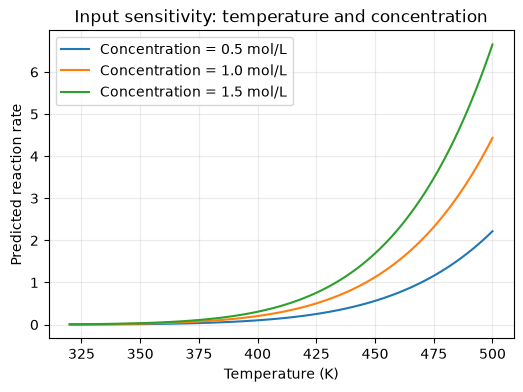

In [19]:
# Sensitivity analysis in the final part of Chapter 7
temperature_grid = np.linspace(320, 500, 100)

plt.figure(figsize=(6, 4))

for concentration in [0.5, 1.0, 1.5]:
    rate_curve = (
        k0_fit
        * np.exp(-Ea_fit / (R * temperature_grid))
        * concentration
    )
    plt.plot(
        temperature_grid,
        rate_curve,
        label=f"Concentration = {concentration} mol/L",
    )

plt.xlabel("Temperature (K)")
plt.ylabel("Predicted reaction rate")
plt.title("Input sensitivity: temperature and concentration")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

- The horizontal axis shows temperature.
- The vertical axis shows the reaction rate calculated by the model.
- Blue, orange, and green curves represent three concentrations.

At the same temperature, the green curve lies above the blue curve: the model calculates a higher rate when concentration increases. The blue curve also rises with temperature. Thus the plot answers: “What does the model calculate when temperature changes?” and “What does it calculate when concentration changes?”

In [20]:
# Generate samples over the possible input ranges
N = 5000
sobol_rng = np.random.default_rng(123)

A = np.column_stack((
    sobol_rng.uniform(320, 500, N),  # temperature (K)
    sobol_rng.uniform(0.2, 2.0, N),  # concentration (mol/L)
))
B = np.column_stack((
    sobol_rng.uniform(320, 500, N),
    sobol_rng.uniform(0.2, 2.0, N),
))

def fitted_rate(inputs):
    T_values = inputs[:, 0]
    C_values = inputs[:, 1]
    return k0_fit * np.exp(-Ea_fit / (R * T_values)) * C_values

# Replace one input at a time in A with the corresponding values from B
A_T = A.copy()
A_T[:, 0] = B[:, 0]

A_C = A.copy()
A_C[:, 1] = B[:, 1]

rate_A = fitted_rate(A)
rate_B = fitted_rate(B)
rate_A_T = fitted_rate(A_T)
rate_A_C = fitted_rate(A_C)

variance = np.var(np.concatenate((rate_A, rate_B)), ddof=1)

S_T = np.mean(rate_B * (rate_A_T - rate_A)) / variance
S_C = np.mean(rate_B * (rate_A_C - rate_A)) / variance

ST_T = np.mean((rate_A - rate_A_T) ** 2) / (2 * variance)
ST_C = np.mean((rate_A - rate_A_C) ** 2) / (2 * variance)

print(f"Temperature:     S1={S_T:.3f}, ST={ST_T:.3f}")
print(f"Concentration: S1={S_C:.3f}, ST={ST_C:.3f}")

Temperature:     S1=0.761, ST=0.919
Concentration: S1=0.101, ST=0.251


Sobol analysis asks how much of the variation in model output comes from each input. We varied temperature and concentration within selected ranges and divided variation in reaction rate between them. S1 represents the effect of an input alone; ST includes its individual effect and interactions with other inputs:

- Temperature: S1 = 0.761, ST = 0.919. Approximately 76% of output variation is attributed to temperature alone; its total effect including interactions is approximately 92%.
- Concentration: S1 = 0.101, ST = 0.251. Its individual effect is approximately 10%, and its total effect including interactions is approximately 25%.

ST is greater than S1 because it also includes effects produced jointly by inputs. In this equation, temperature and concentration combine in the reaction-rate calculation.